# Sélection bibliographique des molécules les plus impactantes pour l'eau

**Objectif :** étape préliminaire et indépendante de **réduction de variables**.
La base achats de pesticides contient **511 substances actives**, ce qui est beaucoup trop élevé pour des croisements statistiques ou économétriques (94 départements / zones hydrographiques).

À partir de la **littérature scientifique sur le lien pesticides ↔ qualité biologique des cours d'eau** et des **listes réglementaires eau françaises et européennes**, ce notebook réduit les **511 substances à 10 molécules clés** (−98 % de variables) tout en couvrant :
- les **3 grandes familles** de pesticides (**4 herbicides, 3 fongicides, 3 insecticides**),
- les **3 bio-indicateurs Hub'Eau** du projet (**`IBD`** diatomées, **`I2M2`** macro-invertébrés, **`IPR`** poissons),
- les **substances les plus fréquemment détectées** et les **plus écotoxiques** dans les rivières françaises sur 2013–2023.

*(L'étape suivante consistera à relier ces 10 molécules aux 23 `libelle_groupe` du RPG.)*

## 1. Sources scientifiques et réglementaires

### Travaux scientifiques de référence (revues à comité de lecture & expertises)

| Référence (lien direct) | Résultat principal pour notre sujet | Bio-indicateur concerné |
|---|---|---|
| [**Beketov et al. (2013)**, *PNAS*](https://doi.org/10.1073/pnas.1305618110) — *Pesticides reduce regional biodiversity of stream invertebrates* | Étude menée en Europe (dont la France) : les pesticides agricoles réduisent jusqu'à **−42 %** la richesse taxonomique régionale des macro-invertébrés des cours d'eau, même sous les seuils réglementaires. | **`I2M2`** (macro-invertébrés) |
| [**Malaj et al. (2014)**, *PNAS*](https://doi.org/10.1073/pnas.1321082111) — *Organic chemicals jeopardize the health of freshwater ecosystems on the continental scale* | Analyse sur ~4 000 sites européens : les polluants organiques — majoritairement des pesticides — entraînent un risque chronique sur **42 %** des sites et un risque aigu sur **14 %** (insecticides pyréthrinoïdes/organophosphorés et herbicides en tête). | **`I2M2`**, **`IBD`**, **`IPR`** |
| [**Stehle & Schulz (2015)**, *PNAS*](https://doi.org/10.1073/pnas.1500232112) — *Agricultural insecticides threaten surface waters at the global scale* | Méta-analyse mondiale (838 études, > 2 500 sites) : les insecticides agricoles dépassent fréquemment les seuils réglementaires dans les eaux de surface ; la richesse en familles d'invertébrés chute d'environ **−30 %** dès ces seuils. | **`I2M2`** (macro-invertébrés), **`IPR`** (poissons) |
| [**Larras et al. (2012)**, *PLOS ONE*](https://doi.org/10.1371/journal.pone.0044458) (INRAE) — *Using Bioassays and Species Sensitivity Distributions to Assess Herbicide Toxicity towards Benthic Diatoms* | Travaux français sur les **diatomées benthiques** : les herbicides inhibiteurs du photosystème II (*isoproturon, diuron, chlortoluron*), le *S-métolachlore* et le *glyphosate* modifient directement la structure des communautés de diatomées en rivière. | **`IBD`** (diatomées) |
| [**Expertise scientifique collective INRAE–Ifremer (2022)**](https://doi.org/10.17180/0gp2-cd65) — *Impacts des produits phytopharmaceutiques sur la biodiversité et les services écosystémiques* | Synthèse de > 4 000 publications : confirme la contamination généralisée des cours d'eau français, la sensibilité aiguë des invertébrés aux **néonicotinoïdes et pyréthrinoïdes**, celle des microalgues aux **herbicides et au cuivre**, et les effets chroniques sur les **poissons** (organophosphorés, pyréthrinoïdes, fongicides triazoles). | **`I2M2`**, **`IBD`**, **`IPR`** |

### Cadres réglementaires et bilans de surveillance français / européens

- [**Directive 2013/39/UE (EUR-Lex)**](https://eur-lex.europa.eu/eli/dir/2013/39/oj) (modifiant la DCE 2000/60/CE) : définit les **Substances Prioritaires (SP / SDP)** qui déclassent l'état chimique des cours d'eau (ex. *isoproturon, cyperméthrine, chlorpyriphos-éthyl*).
- [**Arrêté du 27 juillet 2018 (Légifrance)**](https://www.legifrance.gouv.fr/loda/id/JORFTEXT000037347756/) (modifiant l'arrêté du 25/01/2010) : définit les **Polluants Spécifiques de l'État Écologique (PSEE)** en France (ex. *glyphosate, S-métolachlore, chlortoluron, boscalid, tébuconazole, cuivre, imidaclopride*).
- [**Portail Naïades (Eaufrance)**](https://naiades.eaufrance.fr/) et [**bilans SDES — Ministère de la Transition écologique**](https://www.statistiques.developpement-durable.gouv.fr/) : montrent que les **herbicides** représentent **> 80 % des quantifications** en rivière (dominés par le couple *glyphosate/AMPA*, les métabolites du *S-métolachlore* et le *chlortoluron*), suivis de fongicides récurrents (*boscalid, tébuconazole*).

## 2. Sélection des 10 molécules clés (de 511 → 10 variables)

**Règle de sélection (4 critères cumulatifs) :**
1. **Impact biologique documenté** dans la littérature sur au moins un de nos trois indices (`IBD`, `I2M2`, `IPR`).
2. **Statut réglementaire officiel sur l'eau** : classée **Substance Prioritaire DCE** ou **PSEE France** (l'un des deux obligatoire).
3. **Pertinence sur la période 2013–2023 en France** : molécule massivement achetée et/ou détectée dans les bilans SDES (en incluant des molécules majeures retirées en cours de période comme *isoproturon*, *imidaclopride*, *chlorpyriphos-éthyl*, *S-métolachlore*).
4. **Parcimonie maximale** : éviter les doublons chimiques (les **8 sels de cuivre** de la base achats sont regroupés en une seule variable `cuivre`) et ne garder que les représentants les plus emblématiques de chaque famille.

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Se placer à la racine du dépôt (le notebook est dans notebooks/exploration/)
for _parent in [Path.cwd(), *Path.cwd().parents]:
    if (_parent / "src").is_dir():
        os.chdir(_parent)
        break

pd.set_option("display.max_colwidth", 140)
plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e5e5e5",
    "figure.dpi": 110,
})

NB_SUBSTANCES_INITIALES = 511

# Les 10 molécules sélectionnées avec leurs libellés exacts dans la base achats (BNV-D)
SELECTION_10 = [
    # --- 4 HERBICIDES (cible principale : IBD diatomées + > 80 % des détections cours d'eau) ---
    {
        "molecule": "glyphosate",
        "famille": "Herbicide",
        "classe_chimique": "Organophosphonate (foliaire total)",
        "statut_eau": "PSEE France",
        "presence_rivieres_sdes": "Très élevée (n° 1 avec métabolite AMPA)",
        "indice_bio_principal": "IBD (diatomées / biofilms)",
        "sources": "SDES / Eaufrance ; INRAE-Ifremer (2022) ; Arrêté PSEE 2018",
        "libelles_base_pesticides": ["glyphosate"],
    },
    {
        "molecule": "s-metolachlore",
        "famille": "Herbicide",
        "classe_chimique": "Chloroacétamide",
        "statut_eau": "PSEE France",
        "presence_rivieres_sdes": "Très élevée (avec métabolites ESA/OXA)",
        "indice_bio_principal": "IBD (diatomées / microalgues)",
        "sources": "SDES / Eaufrance ; Larras et al. (INRAE) ; INRAE-Ifremer (2022)",
        "libelles_base_pesticides": ["s-metolachlore"],
    },
    {
        "molecule": "isoproturon",
        "famille": "Herbicide",
        "classe_chimique": "Urée substituée (inhibiteur PSII)",
        "statut_eau": "Substance Prioritaire DCE",
        "presence_rivieres_sdes": "Élevée (historique 2013-2017, retiré)",
        "indice_bio_principal": "IBD (diatomées — modèle de référence)",
        "sources": "Directive 2013/39/UE ; Larras et al. (2012, PLOS ONE) ; Pesce et al.",
        "libelles_base_pesticides": ["isoproturon"],
    },
    {
        "molecule": "chlorotoluron",
        "famille": "Herbicide",
        "classe_chimique": "Urée substituée (inhibiteur PSII)",
        "statut_eau": "PSEE France",
        "presence_rivieres_sdes": "Élevée (actif sur 2013-2023)",
        "indice_bio_principal": "IBD (diatomées)",
        "sources": "SDES / Eaufrance ; Arrêté PSEE 2018 ; INRAE-Ifremer (2022)",
        "libelles_base_pesticides": ["chlorotoluron"],
    },
    # --- 3 FONGICIDES (effets chroniques IBD / IPR / I2M2 + sédiments) ---
    {
        "molecule": "cuivre",
        "famille": "Fongicide",
        "classe_chimique": "Métal inorganique (8 sels regroupés)",
        "statut_eau": "PSEE France",
        "presence_rivieres_sdes": "Persistante (accumulation eau / sédiments)",
        "indice_bio_principal": "IBD (algicide) & I2M2 / IPR",
        "sources": "Arrêté PSEE 2018 ; INRAE-Ifremer (2022)",
        "libelles_base_pesticides": [
            "cuivre de l'hydroxyde de cuivre",
            "cuivre de l'oxychlorure de cuivre",
            "cuivre de l'oxychlorure de cuivre (trihydroxychlorure de dicuivre)",
            "cuivre de l'oxyde cuivreux",
            "cuivre du sulfate de cuivre",
            "cuivre du sulfate tetracuivrique et tricalcique",
            "cuivre du sulfate tribasique",
            "cuivre du tallate de cuivre",
        ],
    },
    {
        "molecule": "boscalid",
        "famille": "Fongicide",
        "classe_chimique": "Carboxamide (SDHI)",
        "statut_eau": "PSEE France",
        "presence_rivieres_sdes": "Élevée (fongicide n° 1 dans les bilans SDES)",
        "indice_bio_principal": "IBD / I2M2 / IPR (chronique)",
        "sources": "SDES / Eaufrance ; Arrêté PSEE 2018 ; INRAE-Ifremer (2022)",
        "libelles_base_pesticides": ["boscalid"],
    },
    {
        "molecule": "tebuconazole",
        "famille": "Fongicide",
        "classe_chimique": "Triazole",
        "statut_eau": "PSEE France + Watch List UE",
        "presence_rivieres_sdes": "Élevée (triazole très détecté)",
        "indice_bio_principal": "IPR (poissons — perturbation endocrinienne) & IBD",
        "sources": "SDES / Eaufrance ; Arrêté PSEE 2018 ; INRAE-Ifremer (2022)",
        "libelles_base_pesticides": ["tebuconazole"],
    },
    # --- 3 INSECTICIDES (pression critique sur I2M2 macro-invertébrés & IPR poissons) ---
    {
        "molecule": "imidaclopride",
        "famille": "Insecticide",
        "classe_chimique": "Néonicotinoïde",
        "statut_eau": "PSEE France + Watch List UE",
        "presence_rivieres_sdes": "Élevée (2013-2018, très hydrosoluble)",
        "indice_bio_principal": "I2M2 (macro-invertébrés — toxicité aiguë)",
        "sources": "Beketov et al. (2013, PNAS) ; Stehle & Schulz (2015, PNAS) ; INRAE-Ifremer (2022)",
        "libelles_base_pesticides": ["imidaclopride"],
    },
    {
        "molecule": "cypermethrine",
        "famille": "Insecticide",
        "classe_chimique": "Pyréthrinoïde",
        "statut_eau": "Substance Dangereuse Prioritaire DCE",
        "presence_rivieres_sdes": "Risque aigu élevé même à très faibles doses",
        "indice_bio_principal": "I2M2 (invertébrés) & IPR (poissons — neurotoxique)",
        "sources": "Directive 2013/39/UE ; Malaj et al. (2014, PNAS) ; Stehle & Schulz (2015, PNAS)",
        "libelles_base_pesticides": ["cypermethrine"],
    },
    {
        "molecule": "chlorpyriphos-ethyl",
        "famille": "Insecticide",
        "classe_chimique": "Organophosphoré",
        "statut_eau": "Substance Prioritaire DCE",
        "presence_rivieres_sdes": "Risque aigu majeur (2013-2020, retiré)",
        "indice_bio_principal": "I2M2 (invertébrés) & IPR (poissons)",
        "sources": "Directive 2013/39/UE ; Malaj et al. (2014, PNAS) ; INRAE-Ifremer (2022)",
        "libelles_base_pesticides": ["chlorpyriphos-ethyl"],
    },
]

df_selection = pd.DataFrame(SELECTION_10)
df_selection["nb_libelles_base"] = df_selection["libelles_base_pesticides"].map(len)
df_selection["variantes_base_pesticides"] = df_selection["libelles_base_pesticides"].map(lambda lst: " | ".join(lst))

nb_libelles = int(df_selection["nb_libelles_base"].sum())
print(f"Réduction de dimension : {NB_SUBSTANCES_INITIALES} substances -> {len(df_selection)} molécules clés (-{100 * (1 - len(df_selection) / NB_SUBSTANCES_INITIALES):.1f} %)")
print(f"Libellés exacts regroupés dans la base achats : {nb_libelles} (dont 8 sels de cuivre -> 'cuivre')")

colonnes_vue = [
    "molecule", "famille", "classe_chimique", "statut_eau",
    "presence_rivieres_sdes", "indice_bio_principal", "sources",
]
display(df_selection[colonnes_vue])

Réduction de dimension : 511 substances -> 10 molécules clés (-98.0 %)
Libellés exacts regroupés dans la base achats : 17 (dont 8 sels de cuivre -> 'cuivre')


,molecule,famille,classe_chimique,statut_eau,presence_rivieres_sdes,indice_bio_principal,sources
0,glyphosate,Herbicide,Organophosphonate (foliaire total),PSEE France,Très élevée (n° 1 avec métabolite AMPA),IBD (diatomées / biofilms),SDES / Eaufrance ; INRAE-Ifremer (2022) ; Arrêté PSEE 2018
1,s-metolachlore,Herbicide,Chloroacétamide,PSEE France,Très élevée (avec métabolites ESA/OXA),IBD (diatomées / microalgues),SDES / Eaufrance ; Larras et al. (INRAE) ; INRAE-Ifremer (2022)
2,isoproturon,Herbicide,Urée substituée (inhibiteur PSII),Substance Prioritaire DCE,"Élevée (historique 2013-2017, retiré)",IBD (diatomées — modèle de référence),"Directive 2013/39/UE ; Larras et al. (2012, PLOS ONE) ; Pesce et al."
3,chlorotoluron,Herbicide,Urée substituée (inhibiteur PSII),PSEE France,Élevée (actif sur 2013-2023),IBD (diatomées),SDES / Eaufrance ; Arrêté PSEE 2018 ; INRAE-Ifremer (2022)
4,cuivre,Fongicide,Métal inorganique (8 sels regroupés),PSEE France,Persistante (accumulation eau / sédiments),IBD (algicide) & I2M2 / IPR,Arrêté PSEE 2018 ; INRAE-Ifremer (2022)
5,boscalid,Fongicide,Carboxamide (SDHI),PSEE France,Élevée (fongicide n° 1 dans les bilans SDES),IBD / I2M2 / IPR (chronique),SDES / Eaufrance ; Arrêté PSEE 2018 ; INRAE-Ifremer (2022)
6,tebuconazole,Fongicide,Triazole,PSEE France + Watch List UE,Élevée (triazole très détecté),IPR (poissons — perturbation endocrinienne) & IBD,SDES / Eaufrance ; Arrêté PSEE 2018 ; INRAE-Ifremer (2022)
7,imidaclopride,Insecticide,Néonicotinoïde,PSEE France + Watch List UE,"Élevée (2013-2018, très hydrosoluble)",I2M2 (macro-invertébrés — toxicité aiguë),"Beketov et al. (2013, PNAS) ; Stehle & Schulz (2015, PNAS) ; INRAE-Ifremer (2022)"
8,cypermethrine,Insecticide,Pyréthrinoïde,Substance Dangereuse Prioritaire DCE,Risque aigu élevé même à très faibles doses,I2M2 (invertébrés) & IPR (poissons — neurotoxique),"Directive 2013/39/UE ; Malaj et al. (2014, PNAS) ; Stehle & Schulz (2015, PNAS)"
9,chlorpyriphos-ethyl,Insecticide,Organophosphoré,Substance Prioritaire DCE,"Risque aigu majeur (2013-2020, retiré)",I2M2 (invertébrés) & IPR (poissons),"Directive 2013/39/UE ; Malaj et al. (2014, PNAS) ; INRAE-Ifremer (2022)"


## 3. Résumé visuel de la réduction de variables

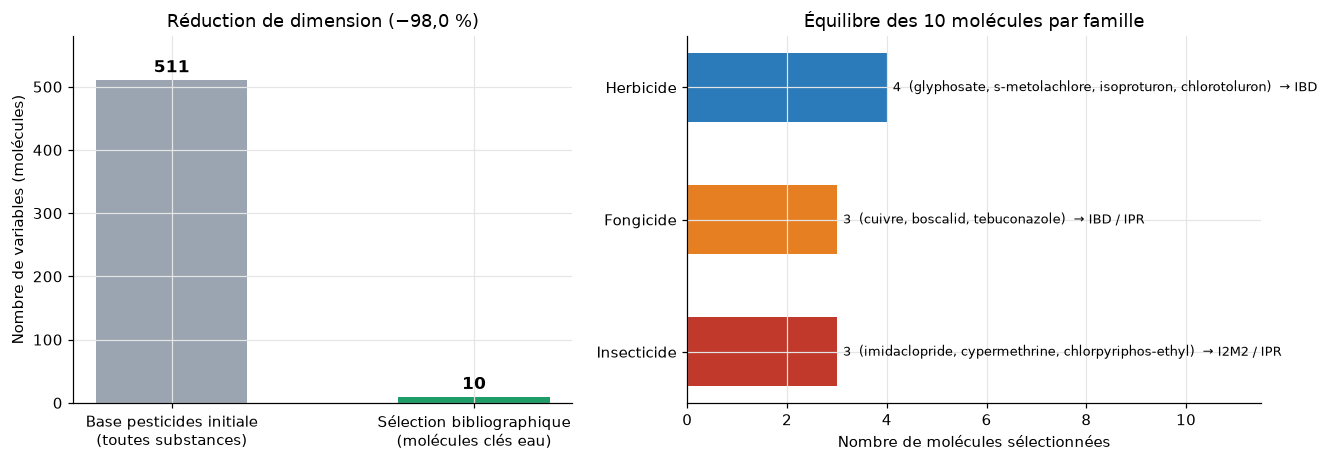

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.3), gridspec_kw={"width_ratios": [1.0, 1.15]})

# 1. Avant / après réduction de variables
labels = ["Base pesticides initiale\n(toutes substances)", "Sélection bibliographique\n(molécules clés eau)"]
vals = [NB_SUBSTANCES_INITIALES, len(df_selection)]
bars = axes[0].bar(labels, vals, color=["#9aa5b1", "#1f9d68"], width=0.5)
axes[0].set_ylabel("Nombre de variables (molécules)")
axes[0].set_title("Réduction de dimension (−98,0 %)")
axes[0].set_ylim(0, 580)
for bar, v in zip(bars, vals):
    axes[0].text(bar.get_x() + bar.get_width() / 2, v + 12, str(v), ha="center", fontweight="bold", fontsize=11)

# 2. Répartition des 10 molécules par famille et bio-indicateur ciblé
ordre_familles = ["Herbicide", "Fongicide", "Insecticide"]
comptes = [int((df_selection["famille"] == f).sum()) for f in ordre_familles]
couleurs = ["#2b7bba", "#e67e22", "#c0392b"]
bars2 = axes[1].barh(ordre_familles[::-1], comptes[::-1], color=couleurs[::-1], height=0.52)
axes[1].set_xlabel("Nombre de molécules sélectionnées")
axes[1].set_title("Équilibre des 10 molécules par famille")
axes[1].set_xlim(0, 5.5)

annotations = {
    "Herbicide": "4  (glyphosate, s-metolachlore, isoproturon, chlorotoluron)  → IBD",
    "Fongicide": "3  (cuivre, boscalid, tebuconazole)  → IBD / IPR",
    "Insecticide": "3  (imidaclopride, cypermethrine, chlorpyriphos-ethyl)  → I2M2 / IPR",
}
for bar, fam in zip(bars2, ordre_familles[::-1]):
    axes[1].text(bar.get_width() + 0.12, bar.get_y() + bar.get_height() / 2, annotations[fam], va="center", fontsize=8.5)
axes[1].set_xlim(0, 11.5)

plt.tight_layout()
plt.show()

## 4. Export de la liste réduite (prête pour l'étape suivante)

On exporte `data/processed/selection_molecules_eau.csv` (10 lignes) et on fournit le dictionnaire
`MAP_VERS_MOLECULE_CLE` permettant de filtrer et regrouper directement la base achats (notamment les 8 formes de cuivre) avant le croisement avec les **23 `libelle_groupe` du RPG**.

In [3]:
dossier_sortie = Path("data/processed")
dossier_sortie.mkdir(parents=True, exist_ok=True)

chemin_csv = dossier_sortie / "selection_molecules_eau.csv"
df_selection.drop(columns=["libelles_base_pesticides"]).to_csv(chemin_csv, index=False, encoding="utf-8-sig")

# Dictionnaire prêt à l'emploi pour filtrer la base pesticides :
# df_pesticides_reduit = df_pesticides[df_pesticides["substance"].isin(MAP_VERS_MOLECULE_CLE)].copy()
# df_pesticides_reduit["molecule_cle"] = df_pesticides_reduit["substance"].map(MAP_VERS_MOLECULE_CLE)
MAP_VERS_MOLECULE_CLE = {
    libelle: row["molecule"]
    for row in SELECTION_10
    for libelle in row["libelles_base_pesticides"]
}

print(f"Exporté : {chemin_csv} ({len(df_selection)} molécules clés, {len(MAP_VERS_MOLECULE_CLE)} libellés BNV-D)")
print("Molécules retenues :", df_selection["molecule"].tolist())

Exporté : data\processed\selection_molecules_eau.csv (10 molécules clés, 17 libellés BNV-D)
Molécules retenues : ['glyphosate', 's-metolachlore', 'isoproturon', 'chlorotoluron', 'cuivre', 'boscalid', 'tebuconazole', 'imidaclopride', 'cypermethrine', 'chlorpyriphos-ethyl']
